In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df= pd.read_csv('/content/heart_disease_risk_dataset_earlymed.csv')

In [58]:
df.head()

,Chest_Pain,Shortness_of_Breath,Fatigue,Palpitations,Dizziness,Swelling,Pain_Arms_Jaw_Back,Cold_Sweats_Nausea,High_BP,High_Cholesterol,Diabetes,Smoking,Obesity,Sedentary_Lifestyle,Family_History,Chronic_Stress,Gender,Age,Heart_Risk
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,48.0,0.0
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,46.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,66.0,0.0
3,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,60.0,1.0
4,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,69.0,0.0


In [59]:
df.shape

(70000, 19)

In [60]:
df.isnull().sum()

,0
Chest_Pain,0
Shortness_of_Breath,0
Fatigue,0
Palpitations,0
Dizziness,0
Swelling,0
Pain_Arms_Jaw_Back,0
Cold_Sweats_Nausea,0
High_BP,0
High_Cholesterol,0


In [61]:
df.duplicated().sum()

np.int64(6245)

In [62]:
df=df.drop_duplicates()

In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
lst=['Chest_Pain','Shortness_of_Breath','Fatigue','Palpitations','Dizziness','Swelling','Pain_Arms_Jaw_Back','Cold_Sweats_Nausea','High_BP','High_Cholesterol','Diabetes','Smoking','Obesity','Sedentary_Lifestyle','Family_History','Chronic_Stress']

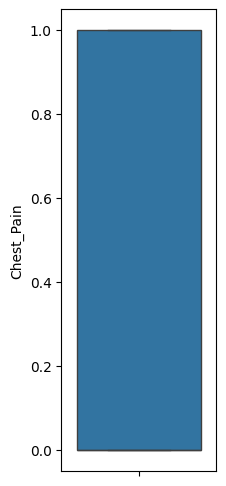

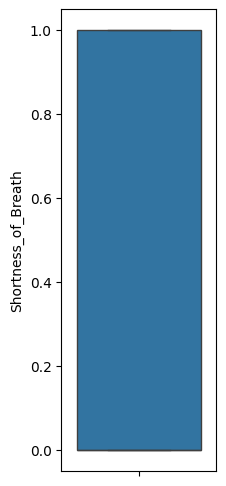

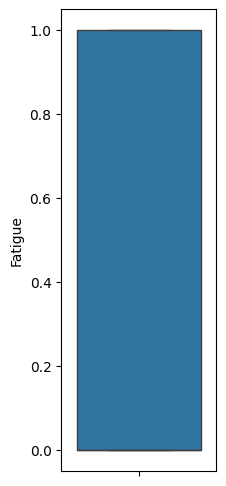

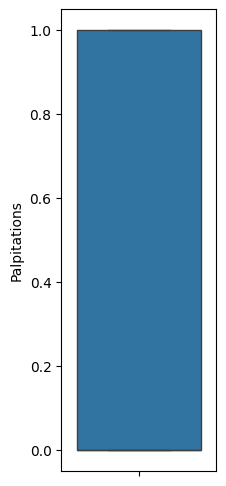

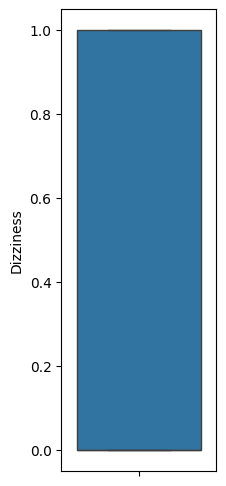

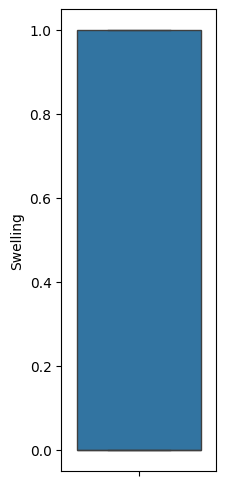

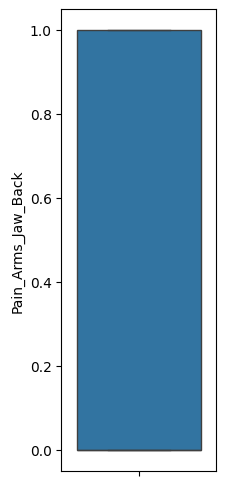

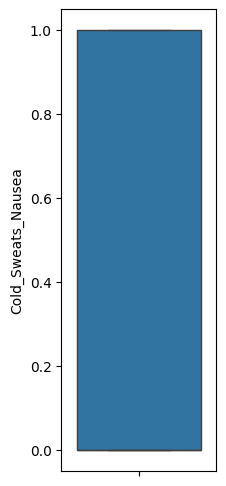

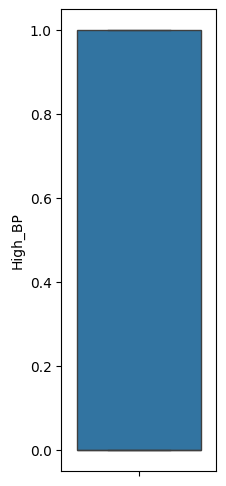

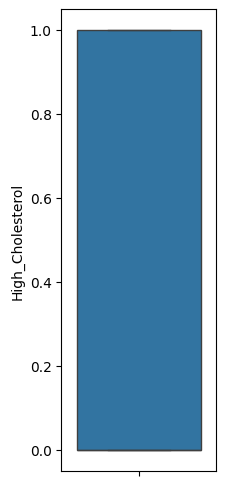

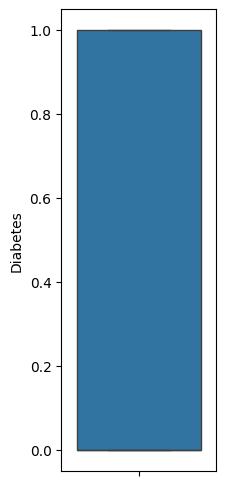

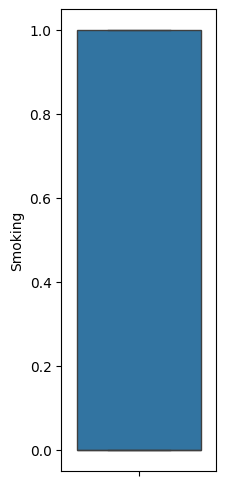

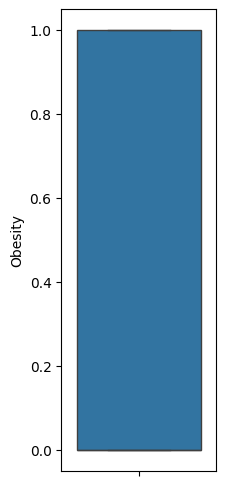

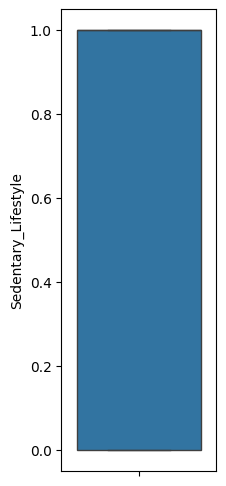

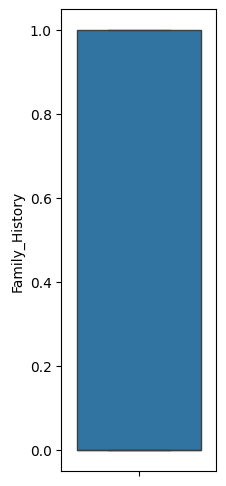

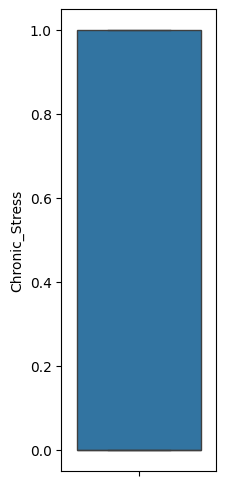

In [65]:
for i in lst:
  plt.figure(figsize=(2,6))
  sns.boxplot(df[i])

In [66]:
for i in lst:
  q3=df[i].quantile(0.75)
  q1=df[i].quantile(0.25)

  IQR= q3-q1


  UL= q3+1.5*(IQR)
  LL=q1-1.5*(IQR)
  df[i]=df[i].clip(LL,UL)

In [67]:
x=df.drop(columns=['Heart_Risk'])

In [68]:
y=df['Heart_Risk']

In [69]:
from sklearn import model_selection
from sklearn.model_selection import train_test_split

X_train,X_test,Y_train,Y_test= train_test_split(x,y,  random_state=2, stratify=y,test_size=0.2)

In [70]:
from sklearn.preprocessing import StandardScaler

Sc= StandardScaler()
X_train=Sc.fit_transform(X_train)
X_test=Sc.transform(X_test)



In [71]:
from sklearn.linear_model import LogisticRegression

Lg= LogisticRegression()
Lg.fit(X_train,Y_train)
Y_pred=Lg.predict(X_test)


In [72]:
df = df.drop_duplicates()

In [74]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [75]:
accuracy_score(Y_test, Y_pred)

0.9910595247431574

In [76]:
precision_score(Y_test, Y_pred)

0.9904807234650167

In [77]:
recall_score(Y_test, Y_pred)

0.9914244878513578

In [78]:
f1_score(Y_test, Y_pred)

0.9909523809523809

In [79]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

In [82]:
model = make_pipeline(StandardScaler(), LogisticRegression())

scores = cross_val_score(model, X_train, Y_train, cv=5)



In [83]:
scores = cross_val_score(
    make_pipeline(StandardScaler(), LogisticRegression()),
    x, y, cv=5
)

In [84]:
scores.mean()

np.float64(0.9908399341228138)

In [85]:
from sklearn.model_selection import GridSearchCV

In [86]:
params = {
    'logisticregression__C': [0.1, 1, 10]
}

In [87]:
grid = GridSearchCV(model, params, cv=5)

grid.fit(x, y)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('logisticregression',
                                        LogisticRegression())]),
             param_grid={'logisticregression__C': [0.1, 1, 10]})

In [88]:
grid.best_params_

{'logisticregression__C': 0.1}

In [89]:
grid.best_score_

np.float64(0.9908399341228138)

In [90]:
from sklearn.model_selection import RandomizedSearchCV

In [91]:
params = {
    'logisticregression__C': [0.01, 0.1, 1, 10, 100]
}

In [92]:
random = RandomizedSearchCV(
    model, params, n_iter=3, cv=5, random_state=2
)

random.fit(x, y)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('standardscaler',
                                              StandardScaler()),
                                             ('logisticregression',
                                              LogisticRegression())]),
                   n_iter=3,
                   param_distributions={'logisticregression__C': [0.01, 0.1, 1,
                                                                  10, 100]},
                   random_state=2)

In [93]:
random.best_params_

{'logisticregression__C': 1}

In [94]:
random.best_score_

np.float64(0.9908399341228138)

In [95]:
from sklearn.ensemble import RandomForestClassifier

In [96]:
RF = RandomForestClassifier(random_state=2)

In [97]:
RF.fit(X_train, Y_train)

RandomForestClassifier(random_state=2)

In [98]:
RF_pred = RF.predict(X_test)

In [99]:
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, RF_pred)

0.9916869265155674

In [100]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(
    x, y, test_size=0.2, random_state=2, stratify=y
)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

model.fit(X_train_raw, Y_train)

grid.fit(X_train_raw, Y_train)
random.fit(X_train_raw, Y_train)

RF.fit(X_train_raw, Y_train)

RandomForestClassifier(random_state=2)

In [101]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Baseline": model,
    "GridSearchCV": grid,
    "RandomizedSearchCV": random,
    "Random Forest": RF
}

results = []

for name, m in models.items():
    pred = m.predict(X_test_raw)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(Y_test, pred),
        "F1 Score": f1_score(Y_test, pred)
    })

comparison = pd.DataFrame(results)

comparison

,Model,Accuracy,F1 Score
0,Baseline,0.991060,0.990952
1,GridSearchCV,0.991216,0.991110
2,RandomizedSearchCV,0.991060,0.990952
3,Random Forest,0.991687,0.991587


In [102]:
comparison.sort_values("F1 Score", ascending=False)

,Model,Accuracy,F1 Score
3,Random Forest,0.991687,0.991587
1,GridSearchCV,0.991216,0.991110
0,Baseline,0.991060,0.990952
2,RandomizedSearchCV,0.991060,0.990952


Random Forest performed slightly better, with 99.17% accuracy and a 99.16% F1 score. GridSearchCV came second, while the baseline model and RandomizedSearchCV gave similar results.

Based on these results, I would choose Random Forest because it achieved the highest scores on the test data.